In [54]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as colors
from matplotlib.lines import Line2D
from pathlib import Path
import sys, os

root = Path.cwd().parent
sys.path.insert(0, str(root))

# 2 Data examination

In [55]:
# TODO: load data file

#######################
f = Path(root / "mp1" / "data" / "isoflops.csv")
isof_te_df = pd.read_csv(f)
#######################

# Choose colormap.
chosen_colormap = cm.magma_r
norm = colors.Normalize(vmin = 18, vmax = 23)
mapper = cm.ScalarMappable(norm = norm, cmap = chosen_colormap)

## (a) Explore the data

In [56]:
# TODO: list all unique value of F
#######################
Fs = list(isof_te_df["flops"].unique())
#######################
print(f"# unique values of F: {len(Fs)}")
print(f"All values of F: {Fs}")

# unique values of F: 9
All values of F: [np.float64(6e+18), np.float64(1e+19), np.float64(3e+19), np.float64(6e+19), np.float64(1e+20), np.float64(3e+20), np.float64(6e+20), np.float64(1e+21), np.float64(3e+21)]


In [57]:
# TODO: print range of F
#######################
print(f"Range of F: {np.ptp(Fs)}")
#######################

Range of F: 2.994e+21


In [58]:
# TODO: print range of number of observations for fixed F
#######################
F_counts = np.unique_counts(isof_te_df["flops"])[1]
print(f"Range in number of observations for fixed F: {np.ptp(F_counts)}")
#######################

Range in number of observations for fixed F: 8


In [59]:
# TODO: print range of P
#######################
Ps = list(isof_te_df["params"])
print(f"Range of P: {np.ptp(Ps)}")
#######################

Range of P: 16126000000.0


## (b) Make a scatter plot of $L$ against $P$

In [60]:
# TODO: group data with the same F
#######################
isof_te = {F: None for F in Fs}
#######################

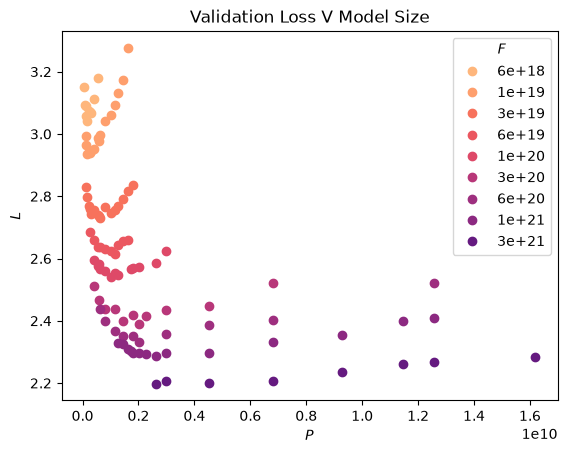

In [61]:
fig, ax = plt.subplots()
for F in Fs:
    F_color = mapper.to_rgba(np.log10(F))
    
    # TODO: scatter plot L against P
    #######################
    subset = isof_te_df.iloc[isof_te_df["flops"] == F]
    ax.scatter(subset["params"], subset["loss"], marker = 'o', facecolor = F_color, edgecolor = F_color)
    #######################

ax.set_title('Validation Loss V Model Size')
ax.set_xlabel(r'$P$')
ax.set_ylabel(r'$L$')

hs = [Line2D([0], [0], marker = 'o', color = 'None', markerfacecolor = F_color, markeredgecolor = F_color) 
      for F_color in mapper.to_rgba(np.log10(Fs))]
ls = Fs
ax.legend(title = r'$F$', handles = hs, labels = ls)
plt.show()

# 3 How should we use the data?

## (c) Make a scatter plot of $L$ against $\log_{10}P$

<>:12: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
<>:12: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
C:\Users\eddyk\AppData\Local\Temp\ipykernel_1400\4091802590.py:12: SyntaxWarning: "\l" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\l"? A raw string is also an option.
  ax.set_xlabel("$\log{P}$")


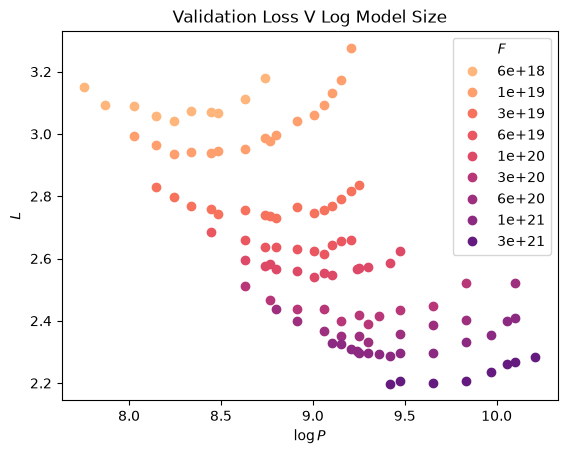

In [62]:
# to do: plot L against log_{10}P
#######################
fig, ax = plt.subplots()

for F in Fs:
    F_color = mapper.to_rgba(np.log10(F))
    
    subset = isof_te_df.iloc[isof_te_df["flops"] == F]
    ax.scatter(np.log10(subset["params"]), subset["loss"], marker = 'o', facecolor = F_color, edgecolor = F_color)

ax.set_ylabel("$L$")
ax.set_xlabel("$\log{P}$")
ax.set_title("Validation Loss V Log Model Size")

hs = [Line2D([0], [0], marker = 'o', color = 'None', markerfacecolor = F_color, markeredgecolor = F_color) 
      for F_color in mapper.to_rgba(np.log10(Fs))]
ls = Fs
ax.legend(title = r'$F$', handles = hs, labels = ls)
plt.show()
#######################

# 4 Modeling

## (a) Define the features

In [63]:
def poly(X, theta, D):
    '''
    evaluate polynomial with input x, and parameters theta
    
    Parameters
    ----------
    x       : (n) numpy.ndarray
              points to evaluate
    theta   : (D+1, 1)
              degree-D polynomial function parameters
       
    Returns
    -------
    (n) numpy.ndarray
        value of polynomial evaluated at x
    '''
    # TODO: implement polynomial evaluation function
    #######################
    X_phi = np.vander(np.log10(X), D + 1, increasing=True)
    out = X_phi @ theta

    return out
    #######################

## (c) Fit $L$ against $P$ with transformed labels and polynomial features

In [64]:
def poly_fit(X, Y, D):
    X_phi = np.vander(np.log10(X), D + 1, increasing=True)
    theta_hat = np.linalg.solve(X_phi.T @ X_phi, X_phi.T @ Y.reshape(-1, 1))
    return theta_hat

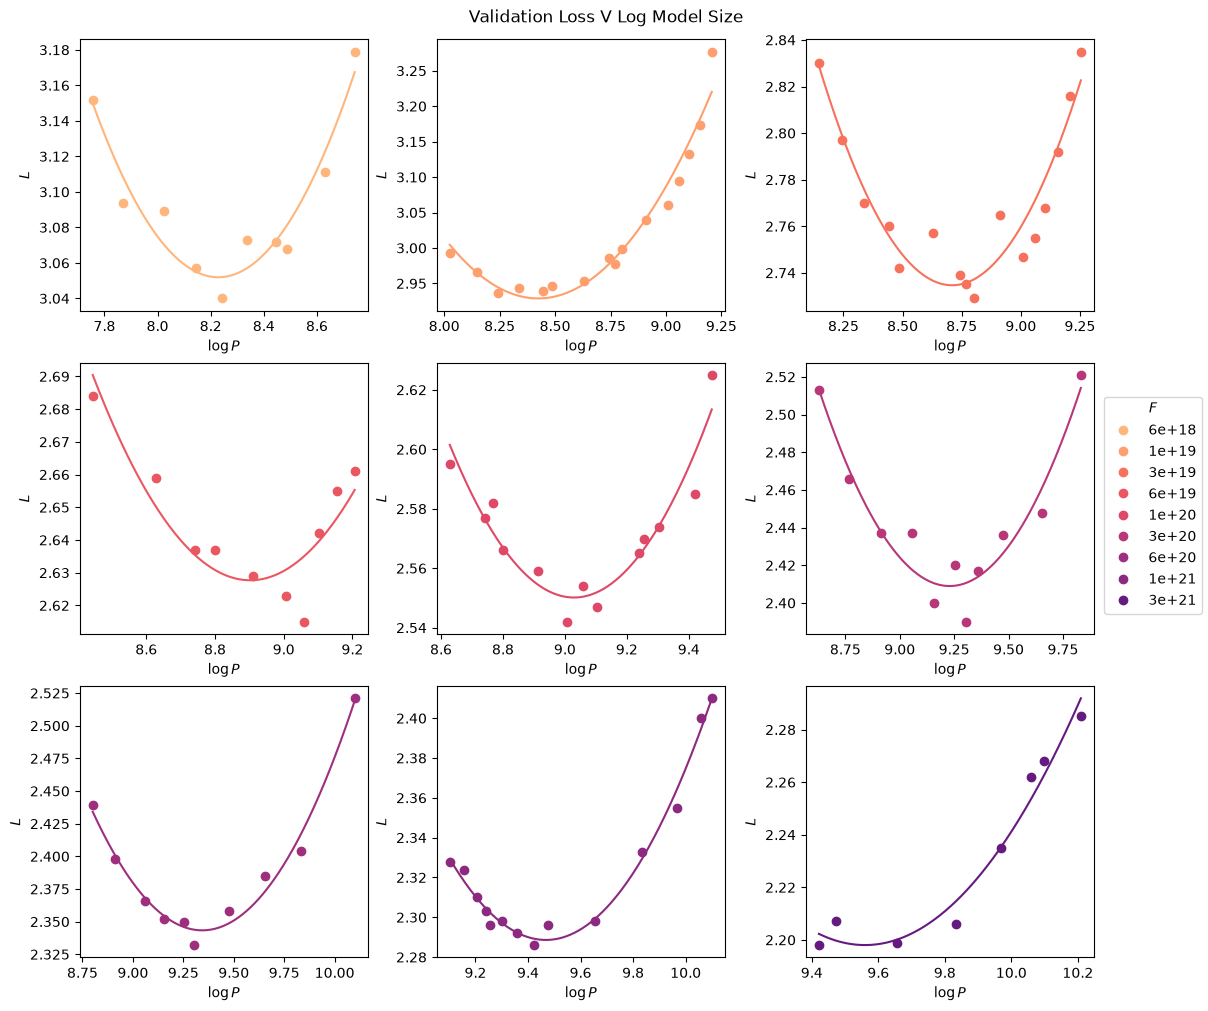

In [65]:
# TODO: plot L against P with appropriate feature transformation as well as curve fits for each F
#######################

fig, ax = plt.subplots(3, 3, figsize = (12, 10), layout = "constrained")
ax = ax.flatten()

for i in range(9):
    F = Fs[i]
    F_color = mapper.to_rgba(np.log10(F))
    subset = isof_te_df.iloc[isof_te_df["flops"] == F]

    X = subset["params"].to_numpy()
    Y = subset["loss"].to_numpy()
    theta_hat = poly_fit(X = X, Y = Y, D = 2)
    # evaluate the fit on a dense, sorted grid so the curve is smooth
    P_grid = np.logspace(np.log10(X.min()), np.log10(X.max()), 200)
    Y_hat = poly(X = P_grid, theta = theta_hat, D = 2).ravel()

    ax[i].scatter(np.log10(X), Y, marker = 'o', facecolor = F_color, edgecolor = F_color)
    ax[i].plot(np.log10(P_grid), Y_hat, color = F_color)
    ax[i].set_ylabel("$L$")
    ax[i].set_xlabel(r"$\log{P}$")

hs = [Line2D([0], [0], marker = 'o', color = 'None', markerfacecolor = F_color, markeredgecolor = F_color) 
      for F_color in mapper.to_rgba(np.log10(Fs))]
ls = Fs

fig.suptitle("Validation Loss V Log Model Size")
fig.legend(title = r'$F$', handles = hs, labels = ls, loc = "outside right center")
plt.show()
#######################

## (d) Find the minimizer $\hat{P}^\text{opt}_F$ for each $F$ and make a scatter plot of $\hat{P}^\text{opt}_F$ against $F$ with appropriate transformations

In [66]:
# TODO: find the minimizer for each F
#######################
P_tilde_opt = []

for i in range(len(Fs)):
    F = Fs[i]
    subset = isof_te_df.iloc[isof_te_df["flops"] == F]
    
    X = subset["params"].to_numpy()
    Y = subset["loss"].to_numpy()
    theta_hat = poly_fit(X = X, Y = Y, D = 2)
    P_grid = np.logspace(np.log10(X.min()), np.log10(X.max()), 200)
    Y_hat = poly(X = P_grid, theta = theta_hat, D = 2).ravel()
    opt = np.argmin(Y_hat)
    P_tilde_opt.append(P_grid[opt])

P_tilde_opt = np.array(P_tilde_opt)
#######################

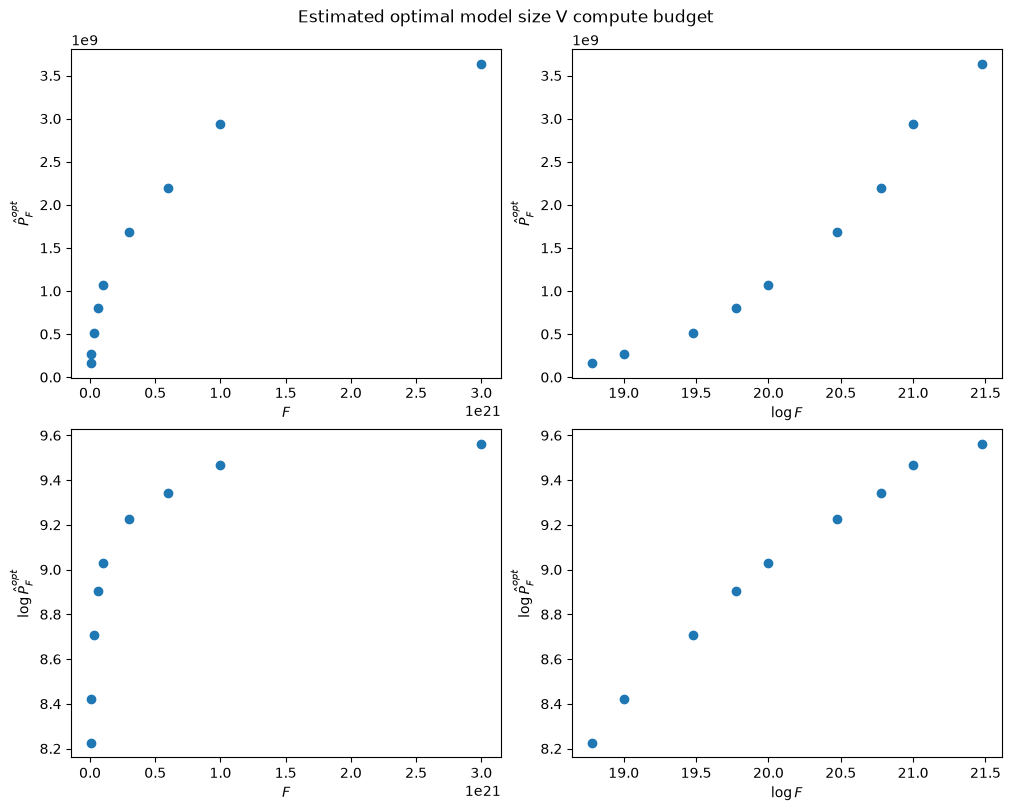

In [75]:
# TODO: plot P^\text{opt}_F against F with appropriate axis scaling choice
#######################
fig, ax = plt.subplots(2, 2, figsize = (10, 8), layout = "constrained")

# every combination of (log10 or raw) on each axis
for row, log_y in enumerate([False, True]):
    for col, log_x in enumerate([False, True]):
        x = np.log10(Fs) if log_x else Fs
        y = np.log10(P_tilde_opt) if log_y else P_tilde_opt

        ax[row, col].scatter(x, y)
        ax[row, col].set_xlabel(r"$\log{F}$" if log_x else "$F$")
        ax[row, col].set_ylabel(r"$\log{\hat{P}^{opt}_F}$" if log_y else r"$\hat{P}^{opt}_F$")

fig.suptitle("Estimated optimal model size V compute budget")
plt.show()
#######################

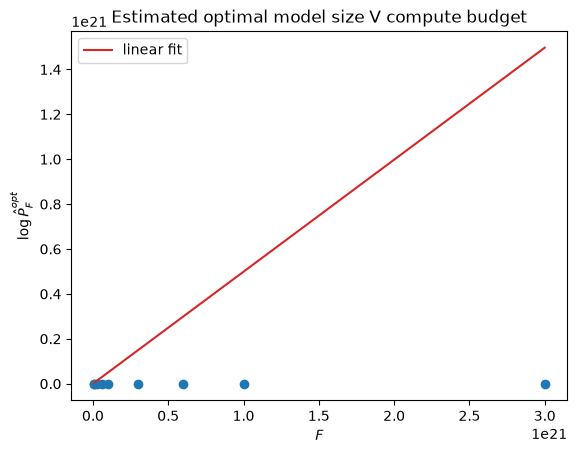

intercept b0 = -1.03355, slope b1 = 0.498929


In [74]:
# linear regression of log10(P_opt) on F: log10(P_opt) = b0 + b1 * F
#######################
fig, ax = plt.subplots()

# np.polyfit rescales the columns internally, which helps when F is very large
b1, b0 = np.polyfit(np.log10(np.asarray(Fs)), np.log10(P_tilde_opt), 1)
F_line = np.linspace(np.min(Fs), np.max(Fs), 200)

ax.scatter(Fs, np.log10(P_tilde_opt))
ax.plot(F_line, b0 + b1 * F_line, color = "tab:red", label = "linear fit")
ax.set_title("Estimated optimal model size V compute budget")
ax.set_xlabel("$F$")
ax.set_ylabel(r"$\log{\hat{P}^{opt}_F}$")
ax.legend()
plt.show()

print(f"intercept b0 = {b0:.6g}, slope b1 = {b1:.6g}")
#######################

## (e) Fit $P^\text{opt}_F$ against $F$ with polynomial features and transformed features and labels

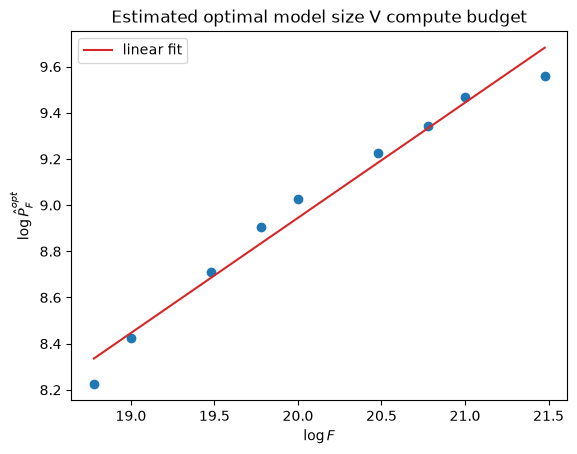

theta_0 = -1.0335, theta_1 = 0.4989


In [77]:
# TODO: plot P^\text{opt}_F against F with appropriate axis scaling choice as well as curve fit
#######################
# log10(P_opt) = theta_0 + theta_1 * log10(F)  <=>  P_opt = 10^theta_0 * F^theta_1
# poly_fit already applies log10 to the features, so we only transform the labels
thetas_P = dict()
thetas_P[1] = poly_fit(X = Fs, Y = np.log10(P_tilde_opt), D = 1)

F_grid = np.logspace(np.log10(np.min(Fs)), np.log10(np.max(Fs)), 200)
logP_hat = poly(X = F_grid, theta = thetas_P[1], D = 1).ravel()

fig, ax = plt.subplots()
ax.scatter(np.log10(Fs), np.log10(P_tilde_opt))
ax.plot(np.log10(F_grid), logP_hat, color = "tab:red", label = "linear fit")
ax.set_title("Estimated optimal model size V compute budget")
ax.set_xlabel(r"$\log{F}$")
ax.set_ylabel(r"$\log{\hat{P}^{opt}_F}$")
ax.legend()
plt.show()

print(f"theta_0 = {thetas_P[1][0, 0]:.4f}, theta_1 = {thetas_P[1][1, 0]:.4f}")
#######################

# 5 Apply the models

## (a) Optimal model size with $1,000,000 budget

In [78]:
# TODO: evaluate optimal model size with $1,000,000 budget
#######################
def predict_P_opt(F):
    return 10 ** poly(X = np.atleast_1d(F), theta = thetas_P[1], D = 1).ravel()

F_budget = 1e20
predict_P_opt(F_budget)[0]
#######################

np.float64(881128220.1779145)

## (b) Optimal model size with $1,000,000 budget and 1,000 times cheaper FLOPs

In [71]:
# TODO: evaluate optimal model size with $1,000,000 budget with 1,000 times cheaper FLOPs
#######################
# same dollars buy 1,000 times more FLOPs
predict_P_opt(1000 * F_budget)[0]
#######################

np.float64(27658393786.853867)

In [80]:
np.max(Fs)

np.float64(3e+21)